# LangChain 멀티모달 RAG 실습 — FashionRAG
### CLIP 이미지 검색 + GPT 비전 모델로 만드는 패션 스타일링 어시스턴트

| 항목 | 내용 |
|---|---|
| 준비물 | OpenAI API 키, 디스크 여유 약 3GB, 인터넷 연결 |
| 결과물 | 한국어로 질문하면 비슷한 패션 사진을 찾아 보여주고 스타일링 조언을 해주는 챗봇 |

**사용법**: 위에서부터 셀을 하나씩 `Shift + Enter` 로 실행하세요. 코드의 주석(`#`)을 꼭 읽으면서 진행하세요.
`✏️ 실습` 셀의 `TODO` 부분은 직접 채워 넣는 문제입니다.


## 학습 목표

1. **멀티모달 RAG** 의 구조(Retrieval → Augmentation → Generation)를 설명할 수 있다.
2. **CLIP** 이 텍스트와 이미지를 같은 벡터 공간에 놓는 원리를 이해하고, 텍스트로 이미지를 검색할 수 있다.
3. **Chroma 벡터 DB** 에 이미지를 저장(`add`)하고 검색(`query`)할 수 있다.
4. **LangChain LCEL**(`프롬프트 | 모델 | 파서`)로 번역 체인과 비전 체인을 만들 수 있다.
5. 이미지를 **base64 data URL** 로 변환해 GPT 비전 모델에 전달할 수 있다.

## 목차

| 파트 | 내용 | 셀 |
|---|---|---|
| 0 | 전체 그림: 멀티모달 RAG 란? | 개념 |
| 1 | 환경 준비 (설치·임포트·API 키·설정값) | [환경]~[4] |
| 2 | 데이터 준비: Fashionpedia 스트리밍 | [5]~[7] |
| 3 | 임베딩 & 벡터 DB: CLIP + Chroma | [8]~[11] |
| 4 | LangChain 체인: 번역 체인 / 비전 체인 | [12]~[13] |
| 5 | 전체 파이프라인 & 대화형 모드 | [14]~[16] |
| 6 | 실습 문제 · 퀴즈 · 정리 | 실습 1~4 |


---
# Part 0. 전체 그림: 멀티모달 RAG

### RAG(Retrieval-Augmented Generation) 복습
LLM 은 학습하지 않은 정보(우리 회사 상품, 최신 데이터 등)를 모릅니다. 그래서 **질문과 관련된 자료를 먼저 찾아서(Retrieval)**, **프롬프트에 붙여 넣고(Augmentation)**, **그 자료를 근거로 답하게(Generation)** 하는 방식이 RAG 입니다.

### 멀티모달(Multimodal) RAG
'모달리티(modality)'는 데이터의 종류(텍스트, 이미지, 음성 …)를 뜻합니다.
일반 RAG 가 **텍스트 문서**를 검색한다면, 멀티모달 RAG 는 **이미지**를 검색하고 **이미지를 볼 수 있는 LLM(비전 모델)** 에게 전달합니다.

### 오늘 만들 FashionRAG 의 흐름

```
 사용자(한국어)  "가을 트렌치코트 스타일링 알려줘"
        │
        ▼  ① 번역 체인 (gpt-4o-mini)           ← LangChain LCEL
 "Trench coat styling for autumn"
        │
        ▼  ② CLIP 텍스트 임베딩 → Chroma 유사도 검색   ← Retrieval
 [image_0123.jpg, image_0456.jpg]   (가장 비슷한 사진 2장)
        │
        ▼  ③ 이미지 → base64 data URL, 질문과 함께 프롬프트 구성  ← Augmentation
        │
        ▼  ④ 비전 체인 (gpt-4o-mini, 이미지 이해)            ← Generation
 "In the first image, the beige trench coat ..."
        │
        ▼  ⑤ 번역 체인
 사용자에게 한국어 답변 + 검색된 사진 출력
```

### 사전 준비 단계 (최초 1회)
```
 Fashionpedia 데이터셋 ──(500장 저장)──▶ fashion_dataset/ 폴더
                                          │  CLIP 이미지 임베딩
                                          ▼
                                   Chroma 벡터 DB (img_vdb/)
```


---
# Part 1. 환경 준비

### 핵심 라이브러리 한눈에 보기
| 라이브러리 | 역할 | 오늘 사용하는 기능 |
|---|---|---|
| **datasets** | Hugging Face 데이터셋 로드 | `load_dataset(..., streaming=True)` |
| **open_clip / torch** | CLIP 모델 실행 | Chroma 의 `OpenCLIPEmbeddingFunction` 내부에서 사용 |
| **chromadb** | 벡터 DB | `PersistentClient`, `add`, `query` |
| **langchain-core** | LLM 앱 구성요소 | `ChatPromptTemplate`, `StrOutputParser`, `|` |
| **langchain-openai** | OpenAI 연결 | `ChatOpenAI` |


In [1]:
# ============================================================
# [환경 준비] 필수 패키지 설치  (최초 1회만 실행)
# ============================================================
# %pip  : '지금 이 노트북 커널'의 파이썬 환경에 패키지를 설치하는 매직 명령어
#         (!pip 는 다른 파이썬 환경에 설치될 수 있으므로 %pip 를 권장)
# -q    : 설치 로그를 간단히(quiet) 출력
%pip -q install "chromadb==1.5.9" open-clip-torch pillow datasets langchain-openai langchain-core python-dotenv
# 패키지별 역할
#   chromadb         : 벡터 데이터베이스 (이미지 임베딩 저장/검색)
%pip -q install chromadb
#   open-clip-torch  : CLIP 모델 (텍스트·이미지를 같은 벡터 공간으로 임베딩)
#                      -> PyTorch(torch)가 함께 설치되어 수 분 걸릴 수 있음
%pip -q install open-clip-torch
#   pillow           : 이미지 열기/저장 (PIL)
%pip -q install pillow
#   datasets         : Hugging Face 데이터셋 다운로드
%pip -q install datasets
#   langchain-core   : 프롬프트 템플릿, 출력 파서, LCEL 체인(|) 등 핵심 기능
%pip -q install langchain-core
#   langchain-openai : LangChain 에서 OpenAI 모델(ChatOpenAI) 사용
%pip -q install langchain-openai
#   python-dotenv    : .env 파일의 환경변수(API 키) 로드
%pip -q install python-dotenv
#
# 설치 후 "Restart Kernel"이 필요하다는 메시지가 나오면 커널을 재시작한 뒤
# 이 셀은 건너뛰고 다음 셀부터 실행하세요.


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


... (6 outputs left out)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ============================================================
# [1] 라이브러리 임포트
# ============================================================

# --- 파이썬 표준 라이브러리 ---
# 파일/폴더 경로 조작, 환경변수 읽기·쓰기
import os
# 이미지(바이너리) -> 텍스트(base64 문자열) 변환
import base64
 # API 키를 화면에 노출하지 않고 입력받기
from getpass import getpass

# --- 환경변수 ---
# .env 파일 내용을 os.environ 으로 불러옴
from dotenv import load_dotenv
# --- 벡터 데이터베이스 (Chroma) ---
import chromadb
# OpenCLIPEmbeddingFunction : 텍스트/이미지를 CLIP 벡터로 바꿔주는 '임베딩 함수'
from chromadb.utils.embedding_functions import OpenCLIPEmbeddingFunction
# ImageLoader : DB에 저장된 이미지 경로(URI)를 실제 이미지 배열로 읽어오는 '데이터 로더'
from chromadb.utils.data_loaders import ImageLoader

# --- 데이터셋 ---
# Hugging Face Hub 데이터셋 로더
from datasets import load_dataset

# --- LangChain ---
# OpenAI 채팅 모델 래퍼
from langchain_openai import ChatOpenAI
# 대화형 프롬프트 템플릿
from langchain_core.prompts import ChatPromptTemplate
# 모델 응답 -> 순수 문자열
from langchain_core.output_parsers import StrOutputParser

# --- 이미지 처리 & 노트북 출력 ---
# 이미지 열기/리사이즈/합치기
from PIL import Image
# 노트북에 이미지·마크다운 예쁘게 출력
from IPython.display import display, Markdown

print("라이브러리 임포트 완료")

c:\workspace\fashionRAG-assistant\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


라이브러리 임포트 완료


In [3]:
# ============================================================
# [2] OpenAI API 키 설정
# ============================================================
# 

load_dotenv()                                   # .env 파일을 찾아 환경변수로 등록
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")    # 환경변수에서 키 읽기 (없으면 None)

if not OPENAI_API_KEY:
    # .env 도 환경변수도 없으면 직접 입력받음 (입력 내용은 화면에 표시되지 않음)
    OPENAI_API_KEY = getpass("OpenAI API 키를 입력하세요 (sk-...): ").strip()

if not OPENAI_API_KEY:
    # 그래도 비어 있으면 더 진행할 수 없으므로 명확한 에러를 발생시킴
    raise ValueError("OPENAI_API_KEY 가 설정되지 않았습니다. .env 파일 또는 입력으로 설정하세요.")

# ChatOpenAI 는 환경변수 OPENAI_API_KEY 를 자동으로 읽어 사용함
os.environ["OPENAI_API_KEY"] = OPENAI_API_KEY

# 키 전체를 출력하면 보안상 위험하므로 앞 6자리만 확인용으로 출력
print("API 키 설정 완료:", OPENAI_API_KEY[:6] + "...")

API 키 설정 완료: sk-pro...


### 설정값을 한 곳에 모으는 이유
경로·모델명·개수 같은 값이 코드 곳곳에 흩어져 있으면 바꾸기 어렵습니다. **맨 위 설정 셀만 고치면** 전체 동작이 바뀌도록 만드는 것이 좋습니다.


In [4]:
# ============================================================
# [3] 실습 설정값 (한 곳에서 관리)
# ============================================================
# 원본 스크립트의 os.path.abspath(__file__) 는 .py 파일에서만 동작합니다.
# 주피터 노트북에는 __file__ 변수가 없으므로(NameError) 현재 작업 폴더를 기준으로 합니다.
BASE_DIR = os.getcwd()

# 이미지를 저장할 폴더
DATASET_FOLDER  = os.path.join(BASE_DIR, "fashion_dataset")   

# Chroma DB 저장 폴더
VDB_PATH        = os.path.join(BASE_DIR, "img_vdb")

# Chroma 컬렉션(=테이블) 이름 (3자 이상, 영문/숫자/._-)
COLLECTION_NAME =  "fashion_images"

NUM_IMAGES = 300       # 데이터셋에서 가져올 이미지 수 (수업 시간이 부족하면 100 정도로 줄이세요)
N_RESULTS  = 2       # 질문 하나당 검색할 이미지 수 (비전 프롬프트에 이미지 2장이 들어감)

# 사용할 OpenAI 모델 이름 
TRANSLATION_MODEL = "gpt-4o-mini"                # 한<->영 번역용 
VISION_MODEL      = "gpt-4o-mini"                # 이미지를 이해하는 비전 모델 

# 이미지로 인식할 확장자 (원본은 .png 만 처리) 
IMAGE_EXTS = (".jpg", ".jpeg", ".png")

print("작업 폴더   :", BASE_DIR)
print("이미지 폴더 :", DATASET_FOLDER)
print("벡터DB 폴더 :", VDB_PATH)

작업 폴더   : c:\workspace\fashionRAG-assistant
이미지 폴더 : c:\workspace\fashionRAG-assistant\fashion_dataset
벡터DB 폴더 : c:\workspace\fashionRAG-assistant\img_vdb


In [5]:
# ============================================================
# [4] 보조 함수: 이미지 파일 목록 / 썸네일 그리드 출력 / MIME 추정
# ============================================================

def list_image_files(folder):
    """folder 안의 이미지 파일 이름을 '정렬된 리스트'로 반환합니다.

    - 폴더가 없으면 빈 리스트를 반환합니다.
    - 파일명을 image_0001.jpg 처럼 0으로 채워(zero-padding) 저장하기 때문에
      문자열 정렬 결과가 곧 숫자 순서와 같아집니다.
    """
    if not os.path.isdir(folder):
        return []
        print("폴더가 없습니다")
    return sorted(
        f for f in os.listdir(folder)
        if f.lower().endswith(IMAGE_EXTS)
    )
         # 폴더 안의 모든 파일 이름 중
         # 이미지 확장자로 끝나는 것만 선택



def show_image_grid(paths, captions=None, thumb=220):
    """여러 이미지 경로를 받아 가로로 이어 붙인 '썸네일 한 장'으로 노트북에 출력합니다.
    (matplotlib 없이 PIL 만으로 구현)"""
    thumbs=[]
    for p in paths:
        img = Image.open(p).convert("RGB")
        img.thumbnail((thumb, thumb))
        thumbs.append(img)
    if not thumbs:
        print("표시할 이미지가 없습니다.")
        return 

    # 가로로 나란히 붙일 빈 캔버스 생성 (흰 배경, 이미지 사이 10px 여백)
    gap = 10 # 단위는 px 단위임
    width = sum(t.width for t in thumbs) + gap*(len(thumbs)-1)
    height = max(t.height for t in thumbs)
    canvas = Image.new("RGB",(width,height), 'white')
    x = 0
    for t in thumbs:
        canvas.paste(t,(x,0))
        x += t.width + gap
    display(canvas)
    if captions:
        print("|".join(captions))


def guess_mime(path):
    """파일 확장자로 이미지 MIME 타입을 추정합니다. (data URL 만들 때 사용)"""
    ext = os.path.splitext(path)[1].lower()
    return "image/png" if ext == ".png" else "image/jpeg"

print("보조 함수 정의 완료")

보조 함수 정의 완료


> **나의 메모** : 
>
> - 경로·모델명·개수 같은 설정값을 한 셀에 모아 두면 그 셀만 고쳐서 전체 동작을 바꿀 수 있다.
> - 노트북에는 `__file__`이 없어서 `os.getcwd()`로 기준 폴더를 잡는다.
> - API 키는 `.env` → `load_dotenv()` → `os.getenv()` 순서로 읽고, 없으면 `getpass`로 화면에 안 보이게 입력받는다. 확인할 때도 앞 6자리만 출력한다.
> - `show_image_grid`는 썸네일을 캔버스 한 장에 붙여 **사람이 한눈에 보기 위한** 출력용 함수다. 모델에는 이미지를 각각 따로 보낸다.

---
# Part 2. 데이터 준비 — Fashionpedia

### Fashionpedia 데이터셋
- 일상·셀럽 행사 패션 사진에 **27개 의류 카테고리, 19개 의류 부위, 294개 세부 속성**을 라벨링한 데이터셋 (CC BY 4.0)
- Hugging Face ID: `detection-datasets/fashionpedia` — train 45,623장 / val 1,158장
- 원래는 객체 탐지(Object Detection)용이지만, 오늘은 **사진만** 꺼내서 검색 대상으로 사용합니다.

### 스트리밍(streaming) 모드
| 방식 | 동작 | 500장 쓰려면 |
|---|---|---|
| 일반 `load_dataset(id)` | 전체 파일을 디스크에 받은 뒤 로드 | **약 3.5GB 전부** 다운로드 |
| `load_dataset(id, streaming=True)` | 필요한 만큼만 순서대로 읽어 옴 | 500장 분량만 다운로드 |

`streaming=True` 이면 결과가 `IterableDataset` 이 되어 인덱스 접근(`ds[0]`) 대신 **반복(for)·`.take(n)`** 으로 사용합니다.


In [6]:
# ============================================================
# [5] 데이터셋 불러오기 & 이미지 저장 함수
# ============================================================

def setup_dataset():
    """   Fashionpedia 데이터셋을 '스트리밍' 모드로 연결합니다.    """
    dataset = load_dataset(
        "detection-datasets/fashionpedia",
        split="train",
        streaming=True
    )
    os.makedirs(DATASET_FOLDER, exist_ok=True)
    return dataset


def save_images(dataset, dataset_folder=DATASET_FOLDER, num_images=NUM_IMAGES):
    """스트리밍 데이터셋에서 앞쪽 num_images 장을 JPEG 파일로 저장합니다.
    - dataset.take(n)  : 스트림에서 앞의 n개 샘플만 꺼냄
    - example["image"] : 데이터셋의 'image' 컬럼 -> PIL.Image 객체로 자동 디코딩됨
    - 파일명 image_0001.jpg : 0 패딩으로 정렬 순서 == 번호 순서 보장
      (원본의 image_1.png, image_10.png, image_100.png ... 사전식 정렬 문제 해결)
    - JPEG 저장 : 원본 사진이 JPEG 이므로 PNG 보다 용량이 훨씬 작고,
      이후 OpenAI 로 base64 전송할 때 데이터량도 줄어듦
    """
    saved = 0
    for i, example in enumerate(dataset.take(num_images)):
        image = example["image"]
        file_path = os.path.join(dataset_folder, f"image_{i+1:04d}.jpg")

        image.convert("RGB").save(file_path,format="JPEG", quality=90)
        saved += 1
        if saved % 50 == 0:
            print(f" ... {saved} / {num_images}장 저장")
    print(f"{saved}장의 이미지를 '{dataset_folder}'에 저장완료!")

print("데이터셋 함수 정의 완료")

데이터셋 함수 정의 완료


In [7]:
# ============================================================
# [6] 데이터셋 준비 실행 (이미 저장돼 있으면 건너뜀)
# ============================================================
# 이미 저장된 이미지 목록
existing = list_image_files(DATASET_FOLDER)
if len(existing) >= NUM_IMAGES:
    print(f"이미지 {len(existing)}장이 이미 있습니다. 다운로드를 건너뜁니다.")
else:
    print(f"Fashionpedia 데이터 셋에서 이미지를 다운로드 합니다.")
    dataset = setup_dataset()
    save_images(dataset, DATASET_FOLDER, NUM_IMAGES)

image_files = list_image_files(DATASET_FOLDER)

print("저장된 이미지 수:", len(image_files))
print("파일명 예시   :", image_files[:3])

이미지 300장이 이미 있습니다. 다운로드를 건너뜁니다.
저장된 이미지 수: 300
파일명 예시   : ['image_0001.jpg', 'image_0002.jpg', 'image_0003.jpg']


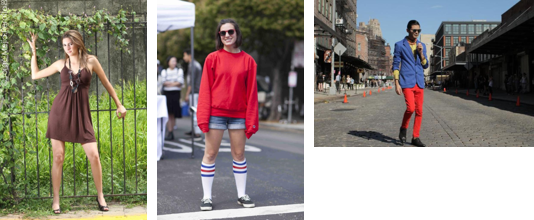

image_0001.jpg|image_0002.jpg|image_0003.jpg


In [8]:
# ============================================================
# [7] 저장된 이미지 미리보기 (데이터가 어떻게 생겼는지 눈으로 확인)
# ============================================================
sample_paths = [os.path.join(DATASET_FOLDER, f) for f in image_files[:3]]
show_image_grid(sample_paths, captions=image_files[:3])

> **나의 메모** :
>
> - Hugging Face에서 `load_dataset(..., streaming=True)`로 불러오면 전체 약 3.5GB를 받지 않고 필요한 만큼만 순서대로 읽는다.
> - 스트리밍 결과는 `IterableDataset`이라 `ds[0]` 같은 인덱스 접근이 안 되고 `.take(n)`과 for문으로 꺼낸다.
> - `example["image"]`는 PIL 이미지로 자동 변환된다. JPEG는 RGBA를 저장하지 못해서 `.convert("RGB")` 후 저장한다.
> - 파일명을 `image_0001.jpg`처럼 0으로 채우면 문자열 정렬 순서와 숫자 순서가 같아진다.

---
# Part 3. 임베딩 & 벡터 DB — CLIP + Chroma

### 임베딩(Embedding)이란?
데이터를 **의미를 담은 숫자 벡터**로 바꾼 것입니다. 의미가 비슷하면 벡터도 가까워집니다.

### CLIP (Contrastive Language-Image Pre-training)
- OpenAI 가 2021년에 발표한 모델 구조이며, 오늘 쓰는 것은 LAION 이 공개 데이터(LAION-2B, 약 20억 쌍)로 학습한 **OpenCLIP ViT-B-32** 입니다.
- **이미지 인코더**와 **텍스트 인코더** 두 개로 구성되며, 둘 다 **512차원** 벡터를 출력합니다.
- 학습 방법(대조 학습): "사진–설명" 짝은 벡터를 **가깝게**, 짝이 아닌 것은 **멀게** 만들도록 학습.
- 결과적으로 **텍스트와 이미지가 같은 공간**에 놓여, `"a red dress"` 텍스트 벡터 근처에 빨간 드레스 사진 벡터들이 모입니다.

```
           512차원 공간 (개념도)
   "a red dress" ●──┐
                    ├─ 가까움 →  📷 빨간 드레스 사진
                    └─ 가까움 →  📷 와인색 원피스 사진
   "a black jacket" ●────────→  📷 검정 재킷 사진   (빨간 드레스와는 멀다)
```

### 벡터 DB — Chroma
| 개념 | 설명 | 코드 |
|---|---|---|
| Client | DB 연결. `PersistentClient` 는 디스크에 저장 | `chromadb.PersistentClient(path=...)` |
| Collection | 테이블 같은 단위 | `get_or_create_collection(name=...)` |
| Embedding Function | 데이터 → 벡터 자동 변환 | `OpenCLIPEmbeddingFunction()` |
| Data Loader | URI(경로) → 실제 데이터 로딩 | `ImageLoader()` |
| add / query | 저장 / 유사도 검색 | `add(ids, uris)`, `query(query_texts, n_results)` |

**`add(uris=...)` 내부 동작**: 경로 → `ImageLoader` 가 이미지 읽기 → CLIP 이미지 인코더 → 벡터 저장
**`query(query_texts=...)` 내부 동작**: 텍스트 → CLIP 텍스트 인코더 → 저장된 이미지 벡터들과 거리 계산 → 가까운 순 반환

### 거리(distance) 읽는 법
- Chroma 기본 거리 함수는 **제곱 유클리드 거리(L2²)** 입니다. **작을수록 비슷**합니다.
- CLIP 벡터는 길이 1로 정규화되어 있어 `L2² = 2 − 2 × 코사인유사도` 관계가 성립 → 순위는 코사인 유사도와 동일합니다.


In [9]:
# ============================================================
# [8] Chroma 벡터 DB 설정 & 이미지 등록 함수
# ============================================================

def setup_chroma_db(vdb_path=VDB_PATH, collection_name=COLLECTION_NAME):
    """CLIP 임베딩 함수를 연결한 Chroma 컬렉션을 생성(또는 기존 것 로드)해 반환합니다."""
    # PersistentClient : 디스크(vdb_path)에 DB를 저장 -> 노트북을 껐다 켜도 유지
    #                    (chromadb.Client() 는 메모리 전용이라 종료 시 사라짐)
    chroma_client = chromadb.PersistentClient(vdb_path)

    # ImageLoader : add/query 때 넘긴 uris(파일 경로)를 실제 이미지(numpy 배열)로 읽어줌
    image_loader = ImageLoader()
    
    # OpenCLIPEmbeddingFunction : 기본값 ViT-B-32 모델 + laion2b_s34b_b79k 가중치
    #   - 첫 실행 시 Hugging Face 에서 약 600MB 가중치를 다운로드 (이후 캐시 사용)
    #   - 텍스트와 이미지를 '같은 512차원 공간'의 벡터로 변환 -> 텍스트로 이미지 검색 가능
    clip = OpenCLIPEmbeddingFunction()

    # get_or_create_collection : 같은 이름의 컬렉션이 있으면 가져오고, 없으면 새로 만듦
    image_vdb = chroma_client.get_or_create_collection(
        name = collection_name,
        embedding_function=clip,
        data_loader=image_loader,
    )
    return image_vdb

# 경로 -> ImageLoader -> 이미지 배열로 변환 -> CLIP 이미지 인코더가 >512차원 벡터 -> img_vdb 폴더에 저장
def add_images_to_db(image_vdb, dataset_folder=DATASET_FOLDER, batch_size=50):
    """폴더의 이미지를 벡터 DB에 등록합니다. 
       이미 등록된 이미지는 건너뜁니다.
    """
    files = list_image_files(dataset_folder)
    ids = [os.path.splitext(f)[0] for f in files]     # 'image_0001.jpg' -> 'image_0001'

    uris = [os.path.join(dataset_folder, f) for f in files]     # 이미지 전체 경로

    # include=[] : 벡터·문서 등은 빼고 id 만 가볍게 조회
    existing_ids = set(image_vdb.get(include=[])["ids"])    
    new_items = [ (i, u) for i, u in zip(ids,uris) if i not in existing_ids]
    if not new_items:
        print(f"추가할 새 이미지가 없습니다. (현재 DB 이미지 수 : {image_vdb.count()})")
        return
    

    print(f"새 이미지 {len(new_items)}장을 임베딩하여 등록합니다. (CPU 기준 수 분 소요)")

    # batch_size 장씩 나눠서 추가 -> 진행 상황 확인 + 메모리 사용량 제한
    for start in range(0, len(new_items), batch_size):
        batch = new_items[start:start + batch_size]
        image_vdb.add(
            ids = [ i for i, _ in batch],
            uris = [u for _, u in batch]
        )
        print(f" ... {min(start + batch_size, len(new_items))}")
    

    
    print(f"이미지가 벡터 데이터베이스에 추가되었습니다. (총 {image_vdb.count()}장)")

print("벡터 DB 함수 정의 완료")

벡터 DB 함수 정의 완료


In [10]:
# ============================================================
# [9] 벡터 DB 생성 및 이미지 등록 실행
# ============================================================
# 컬렉션 생성 또는 로드 (CLIP 모델 로딩 포함)
image_vdb = setup_chroma_db()
add_images_to_db(image_vdb, DATASET_FOLDER)

# 아직 없는 이미지만 임베딩하여 저장

print("컬렉션 이름:", image_vdb.name, "/ 저장된 항목 수:", image_vdb.count())

새 이미지 300장을 임베딩하여 등록합니다. (CPU 기준 수 분 소요)
 ... 50
 ... 100
 ... 150
 ... 200
 ... 250
 ... 300
이미지가 벡터 데이터베이스에 추가되었습니다. (총 300장)
컬렉션 이름: fashion_images / 저장된 항목 수: 300


In [11]:
# ============================================================
# [10] 텍스트로 이미지 검색 & 결과 출력 함수
# ============================================================

def query_db(image_vdb, query, results=N_RESULTS):
    """텍스트 query 와 가장 가까운 이미지를 results 개 검색합니다.

    - query_texts : 검색어 리스트 (여러 개를 한 번에 검색 가능 -> 결과도 2차원 리스트)
    - n_results   : 검색어당 반환할 결과 수
    - include     : 결과에 포함할 항목 ('ids' 는 항상 포함됨)
        'uris'      -> 이미지 파일 경로
        'distances' -> 거리(작을수록 비슷함)
    """
    return image_vdb.query(
        query_texts = [query],
        n_results=results,
        include=["uris", "distances"],
    )
    {
        "ids": [["image_0001", "image_0002"]],
        "uris": [[".../image_0001.jpg",".../image_0002.jpg"]],
        "distances": [[1.52,1.55]]
    }

    r = query_db
    r["ids"][0]
    r["ids"][0][0]
   

def print_results(results):
    """query_db 결과를 사람이 읽기 좋게 출력하고 썸네일도 보여줍니다.
    결과 구조 예시 (검색어 1개, 결과 2개):
      {'ids':       [['image_0042', 'image_0310']],
       'uris':      [['.../image_0042.jpg', '.../image_0310.jpg']],
       'distances': [[1.52, 1.55]]}
      -> 바깥 리스트 = 검색어 순서, 안쪽 리스트 = 순위 순서  =>  [0] 으로 첫 검색어 결과 선택
    """
    uris = results["uris"][0]
    for rank, uri in enumerate(uris):
        print(f"[{rank + 1} 위] ID:{results['ids'][0][rank]}")
        print(f"Distance: {results['distances'][0][rank]:.4f}")
        print(f"Path: {uri}")

    captions = [f"{rank+1} 위 {results['ids'][0][rank]}" for rank in range(len(uris))]
    
    show_image_grid(uris,captions)


   

print("검색 함수 정의 완료")

검색 함수 정의 완료


[1 위] ID:image_0203
Distance: 0.7372
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0203.jpg
[2 위] ID:image_0232
Distance: 0.7505
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0232.jpg
[3 위] ID:image_0181
Distance: 0.7588
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0181.jpg


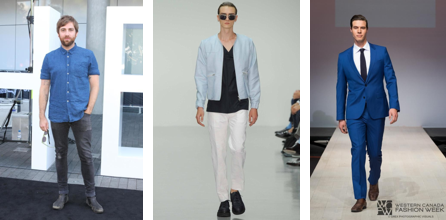

1 위 image_0203|2 위 image_0232|3 위 image_0181


In [12]:
# ============================================================
# [11] 검색 테스트 (OpenAI 없이 CLIP + Chroma 만으로 동작)
# ============================================================
# CLIP 은 주로 영어 데이터로 학습되었으므로 검색어는 '영어'로 넣는 것이 좋습니다.
test_query = "a blue shirts"
results = query_db(image_vdb, test_query, results=3)
print_results(results)


**생각해 보기**: 검색어를 한국어 `"파란 셔츠"` 로 바꿔 [11] 셀을 다시 실행해 보세요. 결과가 어떻게 달라지나요? 왜 그럴까요?

[1 위] ID:image_0136
Distance: 0.7506
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0136.jpg
[2 위] ID:image_0252
Distance: 0.7570
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0252.jpg
[3 위] ID:image_0215
Distance: 0.7571
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0215.jpg


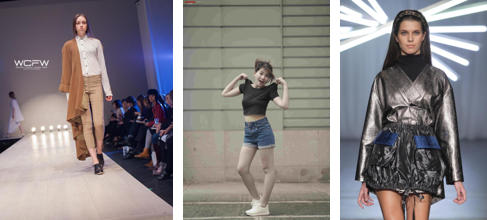

1 위 image_0136|2 위 image_0252|3 위 image_0215


In [13]:
# ============================================================
# [11] 검색 테스트 (OpenAI 없이 CLIP + Chroma 만으로 동작)
# ============================================================
# CLIP 은 주로 영어 데이터로 학습되었으므로 검색어는 '영어'로 넣는 것이 좋습니다.
test_query = "파란 셔츠"
results = query_db(image_vdb, test_query, results=3)
print_results(results)


> **나의 메모** :
>
> - CLIP은 텍스트 인코더와 이미지 인코더가 같은 512차원 공간에 벡터를 만들기 때문에 텍스트로 이미지를 검색할 수 있다.
> - 컬렉션에 `embedding_function`(CLIP)과 `data_loader`(ImageLoader)를 연결하면 `add(ids, uris)`만으로 이미지 읽기 → 임베딩 → 저장이 자동으로 된다.
> - `get(include=[])`로 id만 가볍게 조회해서 이미 등록된 이미지는 건너뛴다. 그래서 폴더를 옮기면 DB에 저장된 옛 경로가 그대로 남는다 → `img_vdb`를 지우고 다시 등록해야 한다.
> - query 결과는 2차원 리스트다. 바깥은 검색어 순서, 안쪽은 순위 순서라서 `[0]`으로 첫 검색어 결과를 꺼낸다.
> - distance는 작을수록 비슷하다. 실제 출력은 0.73~0.76이라 설명에 있는 L2²(1.4~1.6 예상)가 아니라 코사인 거리(1 − 코사인유사도)로 보인다.
>
> **생각해 보기 답**
> - `"a blue shirts"`는 1위 image_0203(0.7372), `"파란 셔츠"`는 1위 image_0136(0.7506)으로 결과가 완전히 달랐다. 그런데 distance는 거의 같았다.
> - 이 CLIP은 영어 캡션으로 학습돼서 한글 문장을 제대로 된 의미 벡터로 만들지 못한다. Top-k는 관련이 없어도 가장 가까운 k장을 항상 돌려주기 때문에 distance만으로는 검색이 실패했는지 알기 어렵다. 그래서 검색 전에 영어로 번역한다.

---
# Part 4. LangChain 체인 — 번역 체인 & 비전 체인

### LCEL (LangChain Expression Language)
`|`(파이프) 연산자로 구성요소를 이어 **체인**을 만듭니다. 앞 단계의 출력이 다음 단계의 입력이 됩니다.

```
 {"text": "...", "target_lang": "English"}   ← invoke() 에 넣는 dict
        │  ChatPromptTemplate  : 변수를 채워 메시지 목록 생성
        ▼
 [SystemMessage, HumanMessage]
        │  ChatOpenAI          : OpenAI API 호출
        ▼
 AIMessage(content="...")
        │  StrOutputParser     : content 만 꺼냄
        ▼
 "..." (str)
```

| 구성요소 | 역할 |
|---|---|
| `ChatPromptTemplate.from_messages([...])` | `("system", ...)`, `("user", ...)` 역할별 메시지 템플릿. `{변수}` 자리표시자 사용 |
| `ChatOpenAI(model, temperature)` | OpenAI 채팅 모델. `temperature` 0 = 일관된 답, 높을수록 다양한 답 |
| `StrOutputParser()` | `AIMessage` → 문자열 |
| `chain.invoke(dict)` | 체인 실행 |


In [14]:
# ============================================================
# [12] 번역 체인 (LCEL: 프롬프트 | 모델 | 파서)
# ============================================================
# 원본은 translate() 를 호출할 때마다 모델·프롬프트·체인을 새로 만들었습니다.
# -> 체인을 '한 번만' 만들고, 목표 언어(target_lang)도 프롬프트 변수로 받아 재사용합니다.
translation_model = ChatOpenAI(model=TRANSLATION_MODEL, temperature=0.0)
# temperature=0.0 : 무작위성 최소화 -> 번역처럼 '정답에 가까운 출력'이 필요할 때 사용

# ChatPromptTemplate.from_messages : (역할, 내용) 튜플 리스트로 대화형 프롬프트 생성
#   {target_lang}, {text} 는 invoke 할 때 채워지는 '자리표시자(변수)'
translation_prompt = ChatPromptTemplate([
("system", "You are a professional translator. "
            "Translate the following text to {target_lang}. "
            "Keep markdown formatting. Output only the translation."),
("user", "{text}"),
])

# | (파이프) 연산자로 구성요소를 연결 = LCEL(LangChain Expression Language)
#   입력 dict -> 프롬프트(메시지 목록) -> 모델(AIMessage) -> 파서(str)
translation_chain = translation_prompt | translation_model | StrOutputParser()

def translate(text, target_lang):
    return translation_chain.invoke({"text": text, "target_lang":target_lang})

# 동작 확인
print(translate("데이트할 때 입을 빨간 원피스", "English"))

Red dress to wear on a date


### 비전 모델에 이미지를 보내는 방법

비전 모델(gpt-4o, gpt-4o-mini)은 user 메시지에 **콘텐츠 블록 리스트**를 받습니다.
```python
[
  {"type": "text",      "text": "질문 ..."},
  {"type": "image_url", "image_url": {"url": "https://... 또는 data:image/jpeg;base64,...."}},
]
```

### base64 와 data URL
- 이미지 파일은 **바이너리(0과 1)** 라서 JSON 텍스트에 바로 넣을 수 없습니다.
- **base64** 는 바이너리를 `A-Z a-z 0-9 + /` 64개 문자로 표현하는 인코딩입니다 (용량은 약 1.33배로 늘어남).
- **data URL** = `data:<MIME 타입>;base64,<base64 문자열>` → 파일을 인터넷에 올리지 않고 URL 자리에 직접 넣을 수 있습니다.
- MIME 타입은 실제 파일 형식과 맞춰야 합니다 (`.jpg` → `image/jpeg`, `.png` → `image/png`).

```
 image_0123.jpg (bytes) ─b64encode─▶ b'/9j/4AAQSk...' ─decode─▶ '/9j/4AAQSk...' (str)
                                                              ─▶ 'data:image/jpeg;base64,/9j/4AAQSk...'
```


In [15]:
# ============================================================
# [13] 비전(멀티모달) 체인: 텍스트 + 이미지 2장을 함께 LLM 에 전달
# ============================================================

def setup_vision_chain():
    """패션 스타일링 조언을 생성하는 '프롬프트 | 비전모델 | 파서' 체인을 반환합니다."""
    # gpt-4o / gpt-4o-mini 는 이미지를 입력으로 이해하는 멀티모달 모델
    vision_model = ChatOpenAI(model=VISION_MODEL, temperature=0.0)
    parser = StrOutputParser

    # system: 모델의 역할·말투 지정
    #  (해석) 당신은 유용한 패션 및 스타일링 보조자입니다. 제공된 이미지의 특정 부분을 직접 언급하며
    #         이미지 컨텍스트를 사용해 질문에 답하세요. 대화하듯 답하고 목록은 너무 많이 쓰지 마세요.
    #         강조와 구조화를 위해 마크다운을 사용하세요.
    #
    # user: '콘텐츠 블록 리스트' 형식 -> 텍스트 블록 1개 + 이미지 블록 2개
    #   이미지 블록의 url 에 data URL(= data:<MIME>;base64,<데이터>)을 넣으면
    #   이미지 파일을 인터넷에 올리지 않고도 모델에 직접 전달할 수 있음
    #   [원본 수정] PNG 파일인데 'image/jpeg' 로 고정 -> 실제 파일 형식(MIME)을 변수로 전달
    image_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "You are a helpful fashion and styling assistant. "
         "Answer the user's question using the given image context with direct references "
         "to parts of the images provided. Maintain a more conversational tone, "
         "don't make too many lists. Use markdown formatting for highlights, emphasis, and structure."),
        ("user", [
            {"type": "text", "text": "What are some ideas for styling {user_query}"},
            {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
            {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
        ]),
    ])
    # 프롬프트 -> 모델 -> 문자열 파서 를 하나의 체인으로 연결해 반환
    return image_prompt | vision_model | parser()


def encode_image(path):
    """이미지 파일을 읽어 base64 문자열로 변환합니다.
    바이너리(bytes) --b64encode--> base64 bytes --decode('utf-8')--> 일반 문자열(str)"""
    # 'rb' = 바이너리 읽기 모드
    with open(path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")


def format_prompt_inputs(data, user_query):
    """검색 결과(data)와 질문으로 비전 프롬프트에 넣을 입력 dict 를 만듭니다.

    반환 예시: {'user_query': '...', 'image_data_1': '/9j/4AAQ...', 'image_mime_1': 'image/jpeg', ...}
    """
    uris = data["uris"][0]              # 첫 번째 검색어의 결과 경로 목록
    
    # 원본 코드는 결과가 2개 미만이면 IndexError 로 중단됨 -> 이해하기 쉬운 메시지로 안내
    if len(uris) < 2:
        raise ValueError(f"이미지가 최소 2장이 필요합니다. 검색결과 {len(uris)}장")

    inputs = {"user_query": user_query}
       
    # 상위 2장만 사용 (n = 1, 2)
    for n, path in enumerate(uris[:2], start=1):
        inputs[f"image_data_{n}"] = encode_image(path)
        inputs[f"image_mime_{n}"] = guess_mime(path)
    return inputs

vision_chain = setup_vision_chain()
print("비전 체인 준비 완료")

비전 체인 준비 완료


---
# Part 5. 전체 파이프라인 조립

지금까지 만든 부품을 RAG 순서대로 연결합니다.

| 단계 | 함수 | RAG 역할 |
|---|---|---|
| ① 질문 번역 | `translate(query_ko, "English")` | 전처리 |
| ② 이미지 검색 | `query_db(image_vdb, query_en)` | **R**etrieval |
| ③ 프롬프트 입력 구성 | `format_prompt_inputs(results, query_en)` | **A**ugmentation |
| ④ 답변 생성 | `vision_chain.invoke(prompt_input)` | **G**eneration |
| ⑤ 답변 번역 | `translate(response_en, "Korean")` | 후처리 |


In [16]:
# ============================================================
# [14] 전체 파이프라인: 한국어 질문 -> 번역 -> 검색 -> 비전 LLM -> 번역 -> 출력
# ============================================================

def ask_fashion_rag(query_ko, n_results=N_RESULTS, show=True):
    """한국어 질문 하나를 받아 FashionRAG 전체 과정을 실행하고 결과 dict 를 반환합니다."""
    # ① 한국어 질문 -> 영어 (CLIP 검색 품질과 LLM 이해도를 높이기 위해)
    query_en = translate(query_ko, "English")

    # ② CLIP 임베딩 기반 이미지 검색 (Retrieval)
    results = query_db(image_vdb, query_en, results = n_results)

    # ③ 검색된 이미지 + 질문을 프롬프트 입력으로 변환 (Augmentation)
    prompt_inputs = format_prompt_inputs(results, query_en)

    # ④ 비전 모델이 이미지를 보고 스타일링 조언 생성 (Generation)
    response_en = vision_chain.invoke(prompt_inputs)

    # ⑤ 영어 답변 -> 한국어
    response_ko = translate(response_en, "Korean")

    if show:
        print("번역된 검색어:", query_en)
        print("\n[검색된 이미지]")
        print_results(results)
        print("\n[FashionRAG 의 응답]")
        display(Markdown(response_ko))   # 마크다운(굵게, 제목 등)을 렌더링해서 출력

    return {"query_en": query_en, "results": results,
            "response_en": response_en, "response_ko": response_ko}

번역된 검색어: Here are some styling tips for men's trench coats that are great for autumn.

[검색된 이미지]
[1 위] ID:image_0188
Distance: 0.7423
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0188.jpg
[2 위] ID:image_0032
Distance: 0.7493
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0032.jpg


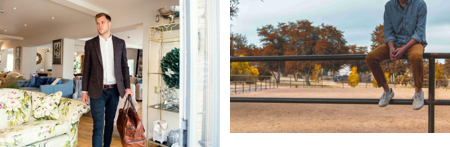

1 위 image_0188|2 위 image_0032

[FashionRAG 의 응답]


트렌치 코트를 가을에 스타일링하면 따뜻하면서도 세련된 룩을 연출할 수 있습니다. 제공된 이미지를 바탕으로 몇 가지 아이디어를 소개합니다:

### 1. **텍스처로 레이어링하기**
첫 번째 이미지에서 남자는 깔끔한 흰 셔츠 위에 텍스처가 있는 블레이저를 입고 있습니다. 이 레이어링 기법은 트렌치 코트와 잘 어울립니다. 트렌치 코트 아래에 **니트 스웨터나 텍스처가 있는 블레이저**를 선택하여 따뜻함과 스타일을 더하세요.

### 2. **스마트 캐주얼 느낌**
첫 번째 이미지의 의상은 스마트 캐주얼 느낌을 주며, 가을에 완벽합니다. 트렌치 코트를 **맞춤형 바지나 치노**와 매치하세요. 네이비나 차콜 같은 어두운 색상은 트렌치와 잘 어울려 조화로운 룩을 만들어냅니다.

### 3. **신발 선택**
**가죽 부츠나 스마트 스니커즈**를 고려해 보세요. 첫 번째 이미지에서 남자는 스타일리시한 가방을 들고 있어 전체적으로 세련된 룩을 더합니다. 슬림한 부츠는 트렌치 코트의 우아함을 강조하면서도 계절에 맞게 실용성을 유지할 수 있습니다.

### 4. **액세서리**
액세서리를 잊지 마세요! **스카프**는 따뜻함과 색감을 더할 수 있습니다. 더 세련된 느낌을 원한다면 **모자**도 고려해 보세요.

### 5. **캐주얼 룩**
두 번째 이미지처럼 더 편안한 분위기를 원한다면, 트렌치 코트를 **데님 셔츠**와 **치노** 위에 입어보세요. 이 조합은 캐주얼한 외출에 완벽하면서도 정돈된 느낌을 줍니다.

### 6. **색상 조화**
가을은 풍부하고 따뜻한 색상이 특징입니다. 버건디, 머스터드, 올리브 그린과 같은 색상을 의상에 포함시켜 보세요. 이러한 색상은 클래식한 트렌치 코트와 잘 어울려 계절에 맞는 룩을 만들어냅니다.

### 7. **핏이 중요하다**
트렌치 코트가 잘 맞는지 확인하세요. 날카롭게 보일 수 있도록 맞춤형이어야 하지만, 아래에 레이어링할 수 있는 여유도 있어야 합니다. 잘 맞는 트렌치 코트는 전체적인 외모에 큰 차이를 만들 수 있습니다.

이 요소들을 조합하여 이번 가을 트렌치 코트로 다양한 스타일리시한 룩을 만들어 보세요!

In [17]:
# ============================================================
# [15] FashionRAG 실행해 보기
# ============================================================
answer = ask_fashion_rag("가을에 입기 좋은 남자 트렌치코트 스타일링 알려줘")

다른 질문으로도 바꿔 실행해 보세요. 예) `"하객룩으로 어울리는 원피스"`, `"캐주얼한 데님 재킷 코디"`, `"여름 휴가지에서 입을 린넨 셔츠"`

In [18]:
# ============================================================
# [16] (선택) 대화형 모드 - 원본 스크립트의 while 루프
# ============================================================
# 노트북에서 input() 무한 루프를 바로 돌리면 '셀 전체 실행' 시 멈춘 것처럼 보이므로
# 기본값은 False 입니다. 직접 대화해 보고 싶을 때만 True 로 바꿔 실행하세요.
RUN_INTERACTIVE = False

if RUN_INTERACTIVE:
    print("FashionRAG 가 여러분의 서비스를 위해 준비되었습니다!")
    while True:
        query_ko = input("\n스타일 질문을 입력하세요 (종료: quit): ").strip()
        if query_ko.lower() in ("quit", "exit", "q", "종료"):
            print("FashionRAG 를 종료합니다.")
            break
        if not query_ko:          # 빈 입력은 무시
            continue
        try:
            ask_fashion_rag(query_ko)
        except Exception as e:    # API 오류 등이 나도 루프가 죽지 않도록 처리
            print("오류가 발생했습니다:", e)
else:
    print("대화형 모드를 사용하려면 RUN_INTERACTIVE = True 로 바꾸고 다시 실행하세요.")

대화형 모드를 사용하려면 RUN_INTERACTIVE = True 로 바꾸고 다시 실행하세요.


> **나의 메모** :
>
> - LCEL은 `prompt | model | parser`처럼 `|`로 연결하고 `invoke(dict)`로 실행한다.
> - 번역 체인은 한 번만 만들고 `target_lang`을 변수로 받아 재사용한다. 번역은 정답에 가까워야 하므로 `temperature=0`.
> - 비전 모델의 user 메시지는 콘텐츠 블록 리스트다. 텍스트 블록 1개 + `image_url` 블록 2개로 구성된다.
> - 이미지 bytes → `b64encode` → `decode` → `data:<MIME>;base64,...` 형태의 data URL로 만든다. MIME은 실제 파일 형식과 맞춘다.
> - 프롬프트 자리표시자와 dict 키 이름이 한 글자라도 다르면 KeyError가 난다(mime → mine 오타). 셀을 고치면 그 셀을 다시 실행해야 커널에 반영된다.

---
# Part 6. ✏️ 실습 문제



### 실습 1. 검색 개수 바꾸기
`"a black leather jacket"` 과 가장 비슷한 사진 **4장**을 찾아 출력하세요.


[1 위] ID:image_0099
Distance: 0.6913
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0099.jpg
[2 위] ID:image_0217
Distance: 0.7071
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0217.jpg
[3 위] ID:image_0245
Distance: 0.7117
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0245.jpg
[4 위] ID:image_0186
Distance: 0.7225
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0186.jpg


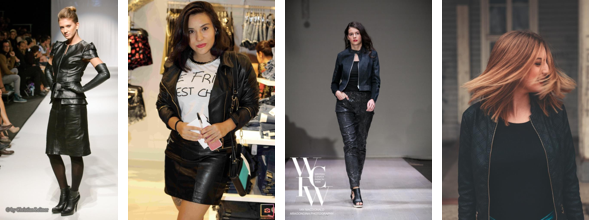

1 위 image_0099|2 위 image_0217|3 위 image_0245|4 위 image_0186


In [23]:
# [실습 1] "a black leather jacket" 과 비슷한 이미지 4장을 검색하고 출력해 보세요.
# 힌트: query_db(컬렉션, 검색어, results=개수) / print_results(결과)
ex1_results = query_db(image_vdb, "a black leather jacket", results=4)
print_results(ex1_results)

### 실습 2. 이미지로 이미지 검색 (Image → Image)
CLIP 은 이미지와 텍스트가 같은 공간에 있으므로, **사진을 검색어로** 넣어 비슷한 사진을 찾을 수도 있습니다. `query_uris` 를 사용해 보세요.

검색에 사용한 이미지: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0006.jpg
[1 위] ID:image_0006
Distance: -0.0000
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0006.jpg
[2 위] ID:image_0171
Distance: 0.1297
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0171.jpg
[3 위] ID:image_0212
Distance: 0.1880
Path: c:\workspace\fashionRAG-assistant\fashion_dataset\image_0212.jpg


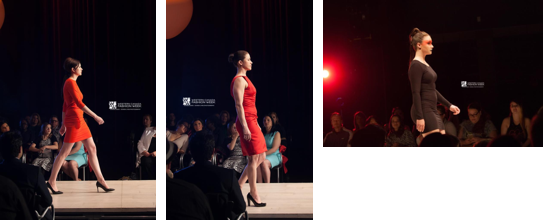

1 위 image_0006|2 위 image_0171|3 위 image_0212


In [25]:
# [실습 2] 이미지로 이미지 검색하기 (Image -> Image)
# CLIP 은 이미지와 텍스트가 같은 벡터 공간에 있으므로 '이미지'로도 검색할 수 있습니다.
# Chroma 의 query() 는 query_texts 대신 query_uris(이미지 경로 리스트)를 받을 수 있습니다.
# 첫 번째 이미지를 검색어로 사용
query_image = os.path.join(DATASET_FOLDER, image_files[5])
print("검색에 사용한 이미지:", query_image)

# TODO: 이미지 경로 '리스트'를 넣으세요
ex2_results = image_vdb.query(
    query_uris=[query_image],
    n_results=3,
    include=["uris", "distances"],
)

print_results(ex2_results)
# 질문: 1위 결과는 무엇이고, distance 는 얼마인가요? 왜 그럴까요?

### 실습 3. 페르소나 바꾸기
system 프롬프트만 바꿔서 **'가성비 스타일리스트'** 챗봇을 만들어 보세요.

In [26]:
# [실습 3] 페르소나 바꾸기: '예산 친화적(가성비) 스타일리스트' 체인 만들기
# 아래 system 메시지를 '저렴한 아이템으로 비슷한 느낌을 내는 방법을 알려주는 스타일리스트'로 바꿔 보세요.
budget_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are a budget-friendly fashion stylist. "
     "Look at the given images and explain how to recreate a similar look with affordable items, "
     "such as basics from fast-fashion brands or secondhand pieces. "
     "Refer directly to parts of the images and suggest a cheaper alternative for each key item. "
     "Keep a conversational tone and use markdown for highlights and emphasis."),
    ("user", [
        {"type": "text", "text": "What are some ideas for styling {user_query}"},
        {"type": "image_url", "image_url": {"url": "data:{image_mime_1};base64,{image_data_1}"}},
        {"type": "image_url", "image_url": {"url": "data:{image_mime_2};base64,{image_data_2}"}},
    ]),
])
budget_model = ChatOpenAI(model=VISION_MODEL, temperature=0.7)
budget_chain = budget_prompt | budget_model | StrOutputParser()

q = translate("출근룩으로 입을 니트", "English")
inputs = format_prompt_inputs(query_db(image_vdb, q), q)
display(Markdown(translate(budget_chain.invoke(inputs), "Korean")))

직장에서 니트웨어를 스타일링하는 것은 세련되면서도 편안할 수 있습니다! 제공하신 이미지를 바탕으로 몇 가지 아이디어를 소개합니다:

### 룩 1: 구조적인 니트 드레스와 아우터웨어
**영감:** 첫 번째 룩은 구조적인 니트 드레스와 세련된 아우터 레이어의 조합입니다.

**재현 방법:**
- **니트 드레스:** 몸에 꼭 맞는 무릎 길이의 니트 드레스를 찾아보세요. H&M이나 Zara와 같은 패스트 패션 브랜드에서 클래식한 색상의 저렴한 옵션을 자주 찾을 수 있습니다.
- **아우터 레이어:** 가벼운 카디건이나 구조적인 블레이저가 좋은 대안이 될 수 있습니다. ASOS나 유니클로와 같은 매장을 확인해 보세요.
- **액세서리:** 간단한 실크 스카프가 룩을 한층 높여줄 수 있습니다. Forever 21과 같은 곳에서 예산에 맞는 스카프를 찾을 수 있습니다.
- **신발:** Payless나 Target에서 클래식 로퍼나 낮은 굽의 펌프스를 선택하여 전문적인 분위기를 유지하세요.

### 룩 2: 캐주얼 니트 스웨터와 재미있는 스커트
**영감:** 두 번째 룩은 캐주얼 니트 스웨터와 세련된 플리츠 스커트를 조합한 것입니다.

**재현 방법:**
- **니트 스웨터:** 중립적인 색상의 아늑하고 오버사이즈 스웨터가 잘 어울립니다. Mango나 Old Navy와 같은 브랜드에서 훌륭한 옵션을 자주 찾을 수 있습니다.
- **플리츠 스커트:** 인조 가죽 또는 플리츠 미디 스커트를 찾아보세요. ASOS나 Shein과 같은 매장에서 저렴한 스타일을 보통 찾을 수 있습니다.
- **타이츠와 신발:** 검은색 타이츠와 앵클 부츠 또는 힐이 있는 부츠와 매치하세요. DSW에서 신발에 대한 좋은 거래를 확인해 보세요.

### 추가 팁:
- **레이어링:** 레이어를 사용하여 차원을 추가하세요—스웨터 아래에 터틀넥을 입거나 드레스 위에 긴 카디건을 입는 것을 생각해 보세요.
- **색상 조화:** 중립색과 포인트 색상을 혼합하기 쉬운 색상 팔레트를 유지하세요.
- **액세서리:** 최소한의 주얼리와 구조적인 가방이 어떤 의상도 더 세련되게 만들어 줄 수 있습니다.

이 팁들을 활용하면 예산을 초과하지 않으면서도 스타일리시하고 직장에 적합한 니트웨어 의상을 쉽게 만들 수 있습니다!

### 실습 4. 거리 임계값 필터
너무 동떨어진 사진은 LLM 에 보내지 않는 것이 좋습니다. distance 가 기준 이하인 결과만 남기는 함수를 완성하세요.

In [27]:
# [실습 4] 거리 임계값(threshold) 필터
# 검색 결과 중 distance 가 기준값 '이하'(=충분히 비슷한)인 결과만 남기는 함수를 완성하세요.
def filter_by_distance(results, max_distance):
    kept = []
    for rid, uri, dist in zip(results["ids"][0], results["uris"][0], results["distances"][0]):
        if dist <= max_distance:            # TODO: 조건을 작성하세요
            kept.append((rid, uri, dist))
    return kept

r = query_db(image_vdb, "a person wearing sunglasses", results=5)
print("전체 거리:", [round(d, 3) for d in r["distances"][0]])
print("필터 결과 (1.5):", filter_by_distance(r, max_distance=1.5))
print("필터 결과 (0.75):", filter_by_distance(r, max_distance=0.75))

전체 거리: [0.747, 0.756, 0.759, 0.769, 0.78]
필터 결과 (1.5): [('image_0185', 'c:\\workspace\\fashionRAG-assistant\\fashion_dataset\\image_0185.jpg', 0.746789813041687), ('image_0263', 'c:\\workspace\\fashionRAG-assistant\\fashion_dataset\\image_0263.jpg', 0.7559882998466492), ('image_0299', 'c:\\workspace\\fashionRAG-assistant\\fashion_dataset\\image_0299.jpg', 0.7587604522705078), ('image_0077', 'c:\\workspace\\fashionRAG-assistant\\fashion_dataset\\image_0077.jpg', 0.7689130902290344), ('image_0003', 'c:\\workspace\\fashionRAG-assistant\\fashion_dataset\\image_0003.jpg', 0.7795319557189941)]
필터 결과 (0.75): [('image_0185', 'c:\\workspace\\fashionRAG-assistant\\fashion_dataset\\image_0185.jpg', 0.746789813041687)]


---
# 확인 퀴즈

1. CLIP 으로 **텍스트로 이미지를 검색**할 수 있는 이유는 무엇인가요?
2. Chroma 에서 `distance` 값이 **작을수록** 의미하는 것은?
3. 이미지를 OpenAI 비전 모델에 보낼 때 **base64 로 인코딩**하는 이유는?
4. `load_dataset(..., streaming=True)` 를 쓰면 무엇이 좋아지나요?
5. 원본 스크립트를 노트북으로 옮겼을 때 `__file__` 에서 에러가 나는 이유는?
6. FashionRAG 에서 번역을 두 번(질문, 답변) 하는 이유는?
7. LCEL 에서 `prompt | model | parser` 각 단계의 **출력 타입**을 순서대로 적어 보세요.

(답을 아래 메모 칸에 적어 보세요)


> **나의 메모** :
>
> 1. CLIP이 대조 학습으로 텍스트와 이미지를 같은 벡터 공간에 놓기 때문에 텍스트 벡터와 이미지 벡터의 거리를 바로 비교할 수 있다.
> 2. distance가 작을수록 질문과 이미지가 의미적으로 더 비슷하다.
> 3. 이미지는 바이너리라 JSON 텍스트 요청에 그대로 넣을 수 없어서 문자열로 바꾸고, data URL로 업로드 없이 직접 전달한다.
> 4. 전체를 다운로드하지 않고 필요한 양만 읽어 디스크와 시간을 아낀다. 대신 인덱스 접근이 안 된다.
> 5. `__file__`은 .py 파일을 스크립트로 실행할 때만 생기는 변수다. 노트북은 커널에서 셀 단위로 실행되어 NameError가 난다.
> 6. 질문 번역은 CLIP이 영어로 학습되어 영어 검색 품질이 좋기 때문이고, 답변 번역은 사용자에게 한국어로 보여주기 위해서다.
> 7. prompt → `ChatPromptValue`(메시지 목록), model → `AIMessage`, parser → `str`.

---
# 정리

| 오늘 배운 것 | 핵심 한 줄 |
|---|---|
| 멀티모달 RAG | 이미지를 검색해서 비전 LLM 의 근거로 사용 |
| CLIP | 텍스트와 이미지를 같은 벡터 공간에 → 텍스트로 이미지 검색 |
| Chroma | `embedding_function` + `data_loader` 로 경로만 넣으면 임베딩·저장 자동 |
| LCEL | `prompt | model | parser`, `invoke(dict)` |
| 비전 입력 | `{"type": "image_url", "image_url": {"url": "data:<MIME>;base64,..."}}` |

### 더 나아가기
- **다국어 CLIP**(예: `xlm-roberta-base-ViT-B-32`)을 쓰면 번역 없이 한국어로 바로 검색 가능
- **메타데이터 필터**: Fashionpedia 의 의류 카테고리를 `metadatas` 로 저장해 `where={"category": "dress"}` 로 필터 검색
- **대화 기억**: `RunnableWithMessageHistory` 로 이전 질문 맥락 유지
- **웹 UI**: Gradio / Streamlit 으로 `ask_fashion_rag()` 를 감싸 웹 데모 만들기
